# 12 · Do the elongated meningeal nuclei lie along the surface?

Notebooks 09–10 showed that the outer ≤ 10 µm of the meninges is rich in elongated, mostly Pu.1⁻ nuclei.
If these are flattened pial / arachnoid cells, their long axis should run **parallel to the tissue
surface**; squashed or cut nuclei at the edge, or cells migrating inward, would point any way or radially.

* **Long axis** of every nucleus from the second moments of its mask in the Cellpose label image (the
  same ellipse as the cell table's eccentricity – they agree exactly).
* **Surface direction** from the fine tissue raster (gradient of the smoothed depth, σ = 5 µm).
* **Surface angle** 0–90°: 0 = along the surface, 90 = pointing into the tissue. Random axes give a
  uniform angle (mean 45°, 1/3 within 30° of the surface).
* **Order parameter S** = mean cos(2 · angle): +1 all parallel, 0 random, −1 all radial.

Only **elongated nuclei** (eccentricity ≥ 0.85) are analysed – a round nucleus has no meaningful axis.
Groups by depth: meninges 0–10 µm (the outer layer), meninges 10–80 µm, parenchyma 20–80 µm under the
surface (**edge control**: same surface, no meninges) and parenchyma 150–300 µm (deep). The section is
the unit (replicate slides averaged); a **shuffle null** pairs each nucleus with the surface direction of
a random other nucleus of the same slide (keeps any slide-wide preferred direction, e.g. from cutting).

In [1]:
import os, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
os.chdir(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
%config InlineBackend.figure_format = 'jpeg'   # image-heavy notebooks: keep files small
plt.rcParams["figure.dpi"] = 80
from lesionseg import report as R
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 120)
RUN_DIR = "outputs/sdata"
runs = R.load_runs(RUN_DIR)
print("scenes:", [r.name for r in runs])

from matplotlib.colors import LinearSegmentedColormap
from lesionseg import expression as E, morphology as M, orientation as O
ex = E.expression_table(runs)
df = O.orientation_table(runs, ex)
df["group"] = O.depth_groups(df)
el = df[(df.eccentricity >= M.ELONG_MIN) & df.group.notna()]
GCOL = dict(zip(O.GROUPS, ["#eb6834", "#eda100", "#3987e5", "#898781"]))
rows = []
for g in O.GROUPS:
    a = el[el.group == g]
    nul = O.shuffled_null(a, 200)
    rows.append({"group": g, "elongated_nuclei": len(a), "S": O.order_parameter(a.surface_angle),
                 "within_30deg_pct": 100 * (a.surface_angle < 30).mean(), "mean_angle_deg": a.surface_angle.mean(),
                 "shuffle_S_low": np.percentile(nul, 2.5), "shuffle_S_high": np.percentile(nul, 97.5)})
summ = pd.DataFrame(rows)
summ.round(3)

scenes: ['CML_1 scene 0', 'CML_2_rescan scene 0', 'CML_metal scene 0', 'CML_metal scene 1']


,group,elongated_nuclei,S,within_30deg_pct,mean_angle_deg,shuffle_S_low,shuffle_S_high
0,meninges 0–10 µm,4399,0.606,74.130,22.447,-0.012,0.028
1,meninges 10–80 µm,1421,0.414,59.324,29.828,0.004,0.073
2,parenchyma 20–80 µm,4788,0.218,46.032,36.995,-0.019,0.019
3,parenchyma 150–300 µm,5624,-0.129,27.294,49.715,-0.036,-0.001


## Angle to the surface, elongated nuclei (dotted = random)

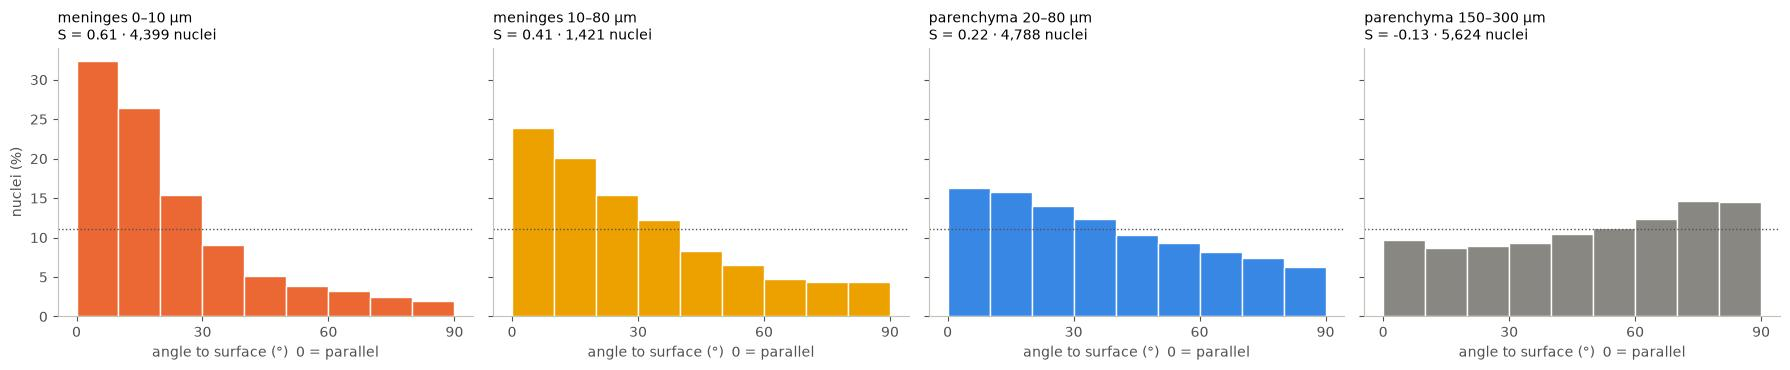

In [2]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8), sharey=True)
bins = np.arange(0, 91, 10)
for ax, g in zip(axes, O.GROUPS):
    a = el[el.group == g].surface_angle
    ax.hist(a, bins=bins, weights=np.full(len(a), 100 / max(len(a), 1)), color=GCOL[g], edgecolor="white")
    ax.axhline(100 / 9, color="#52514e", lw=1, ls=":")
    ax.set_title(f"{g}\nS = {O.order_parameter(a):.2f} · {len(a):,} nuclei", loc="left", fontsize=10)
    ax.set_xlabel("angle to surface (°)  0 = parallel"); ax.set_xticks([0, 30, 60, 90])
axes[0].set_ylabel("nuclei (%)")
plt.tight_layout(); plt.show()

## Alignment against depth below the surface (elongated nuclei, any compartment; per slide)

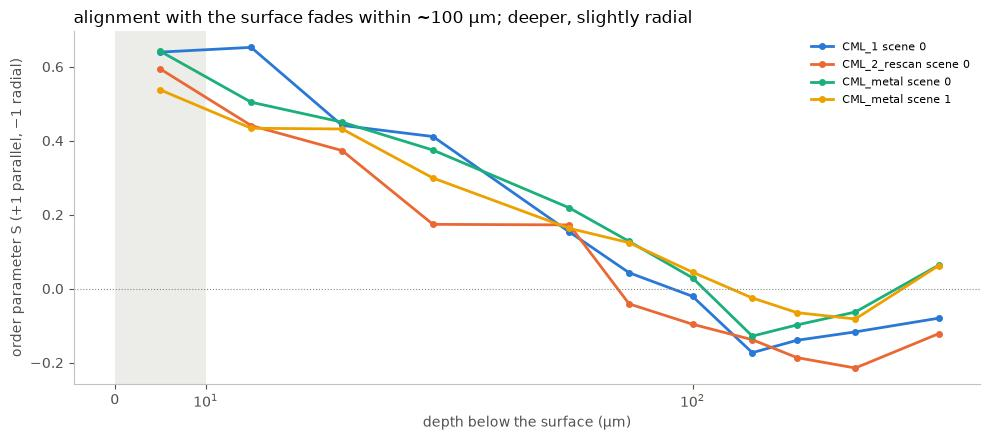

In [3]:
dp = O.depth_alignment(df)
fig, ax = plt.subplots(figsize=(10, 4.5))
for (scene, d), col in zip(dp.groupby("scene"), E.SCENE_COLORS):
    ax.plot(d.mid_um, d["mean"], color=col, lw=2, marker="o", ms=4, label=scene)
ax.axhline(0, color="#898781", lw=0.8, ls=":"); ax.axvspan(0, 10, color="#c3c2b7", alpha=0.3, lw=0)
ax.set_xscale("symlog", linthresh=50)
ax.set_xlabel("depth below the surface (µm)"); ax.set_ylabel("order parameter S (+1 parallel, −1 radial)")
ax.set_title("alignment with the surface fades within ~100 µm; deeper, slightly radial", loc="left"); ax.legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

## Per section (replicate slides averaged)

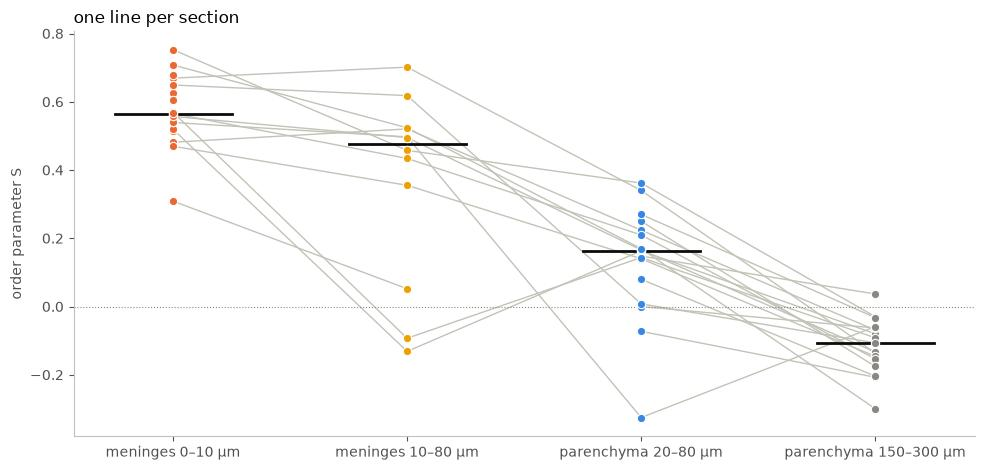

,comparison,sections,animals,median_delta,mean_delta,ci95_low,ci95_high,sections_higher,wilcoxon_p
0,meninges 0–10 µm − meninges 10–80 µm,12,6,0.1231,0.1966,0.0570,0.3618,10,0.0049
1,meninges 0–10 µm − parenchyma 20–80 µm,17,6,0.3912,0.4547,0.3667,0.5667,17,0.0000
2,meninges 0–10 µm − parenchyma 150–300 µm,17,6,0.6902,0.7032,0.6203,0.7884,17,0.0000


,group,meninges 0–10 µm,meninges 10–80 µm,parenchyma 20–80 µm,parenchyma 150–300 µm
section,animal,,,,
CFA_L2_C,CFA_L2,0.51,NaN,0.15,0.04
CFA_L2_L,CFA_L2,0.48,0.52,0.22,-0.07
CFA_L2_T,CFA_L2,0.52,-0.13,0.16,-0.08
OS1_2_,OS1_2,0.56,NaN,-0.00,-0.06
OS1_2_C,OS1_2,0.54,NaN,-0.07,-0.21
OS1_2_L,OS1_2,0.54,0.50,-0.33,-0.06
P2_3_C,P2_3,0.67,0.70,0.34,-0.14
P2_3_L,P2_3,0.56,0.50,0.17,-0.13
P2_3_T,P2_3,0.75,0.46,0.36,-0.03


In [4]:
per = O.section_alignment(df)
t = per.pivot_table(index=["section", "animal"], columns="group", values="S").reindex(columns=O.GROUPS)
fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(O.GROUPS))
for _, row in t.iterrows():
    ax.plot(x, row.to_numpy(float), color="#c3c2b7", lw=1)
for i, g in enumerate(O.GROUPS):
    v = t[g].dropna()
    ax.scatter(np.full(len(v), i), v, s=36, color=GCOL[g], edgecolors="white", linewidths=0.8, zorder=3)
    ax.plot([i - 0.25, i + 0.25], [v.median()] * 2, color="#0b0b0b", lw=2)
ax.axhline(0, color="#898781", lw=0.8, ls=":")
ax.set_xticks(x, O.GROUPS); ax.set_ylabel("order parameter S"); ax.set_title("one line per section", loc="left")
plt.tight_layout(); plt.show()
display(pd.DataFrame([O.paired_test(per, O.GROUPS[0], b) for b in O.GROUPS[1:]]).round(4))
display(t.round(2))

## Robustness: outer meninges vs the edge control under other choices

Each row recomputes S of the outer meningeal layer (0–10 µm) and of parenchyma 20–80 µm under the
surface, per section, and tests the paired difference.

In [5]:
def check(d, ecc=M.ELONG_MIN, **kw):
    p = O.section_alignment(d, ecc_min=ecc, **kw)
    r = O.paired_test(p, O.GROUPS[0], O.GROUPS[2])
    s = p.groupby("group").S.median()
    return {"S_outer_meninges": s.get(O.GROUPS[0]), "S_parenchyma_20_80": s.get(O.GROUPS[2]),
            **{k: r[k] for k in ("sections", "median_delta", "ci95_low", "ci95_high", "sections_higher", "wilcoxon_p")}}
rows = [("default (ecc ≥ 0.85, σ = 5 µm)", check(df))]
rows += [(f"eccentricity ≥ {e}", check(df, ecc=e)) for e in (0.8, 0.9)]
for s in (2, 10, 20):
    rows.append((f"surface smoothing σ = {s} µm", check(O.orientation_table(runs, ex, sigma_um=s).assign(
        group=lambda d: O.depth_groups(d)))))
rows += [("well-segmented only (solidity ≥ 0.9)", check(df[df.solidity >= 0.9])),
         ("Pu.1⁻ nuclei only", check(df[~df.pu1_pos])), ("Pu.1⁺ nuclei only", check(df[df.pu1_pos], min_cells=5)),
         ("lesion sections only", check(df[df.section.isin(ex[ex.compartment.isin(["core", "rim"])].section.unique())])),
         ("control sections only", check(df[~df.section.isin(ex[ex.compartment.isin(["core", "rim"])].section.unique())]))]
rob = pd.DataFrame([{"check": n, **r} for n, r in rows])
rob.round(4)

,check,S_outer_meninges,S_parenchyma_20_80,sections,median_delta,ci95_low,ci95_high,sections_higher,wilcoxon_p
0,"default (ecc ≥ 0.85, σ = 5 µm)",0.5636,0.1632,17,0.3912,0.3667,0.5667,17,0.0000
1,eccentricity ≥ 0.8,0.5319,0.1558,17,0.3705,0.3507,0.4817,17,0.0000
2,eccentricity ≥ 0.9,0.6026,0.2494,15,0.3865,0.3378,0.5445,15,0.0001
3,surface smoothing σ = 2 µm,0.4391,0.1503,17,0.2756,0.2537,0.4309,17,0.0000
4,surface smoothing σ = 10 µm,0.6120,0.1724,17,0.4480,0.4033,0.5984,17,0.0000
5,surface smoothing σ = 20 µm,0.6525,0.1841,17,0.4559,0.4187,0.6051,17,0.0000
6,well-segmented only (solidity ≥ 0.9),0.5801,0.1974,16,0.3771,0.3477,0.5333,16,0.0000
7,Pu.1⁻ nuclei only,0.5395,0.1549,17,0.3922,0.3370,0.5586,17,0.0000
8,Pu.1⁺ nuclei only,0.6514,0.2487,12,0.3736,0.1489,0.5780,11,0.0068
9,lesion sections only,0.6158,0.2299,8,0.3733,0.3474,0.4543,8,0.0078


## Random examples (outer meninges, 140 µm windows, seed 1)

Window centres are random nuclei of the outer meningeal layer (≤ 10 µm deep), kept if the window holds
≥ 8 of them and lies ≥ 300 µm from earlier draws – nothing selected on orientation.
Every elongated nucleus is drawn as a short line along its long axis, coloured by its angle to the
surface: **green = along the surface, pink = pointing into the tissue**, grey = in between. Meninges /
buffer edges as before.

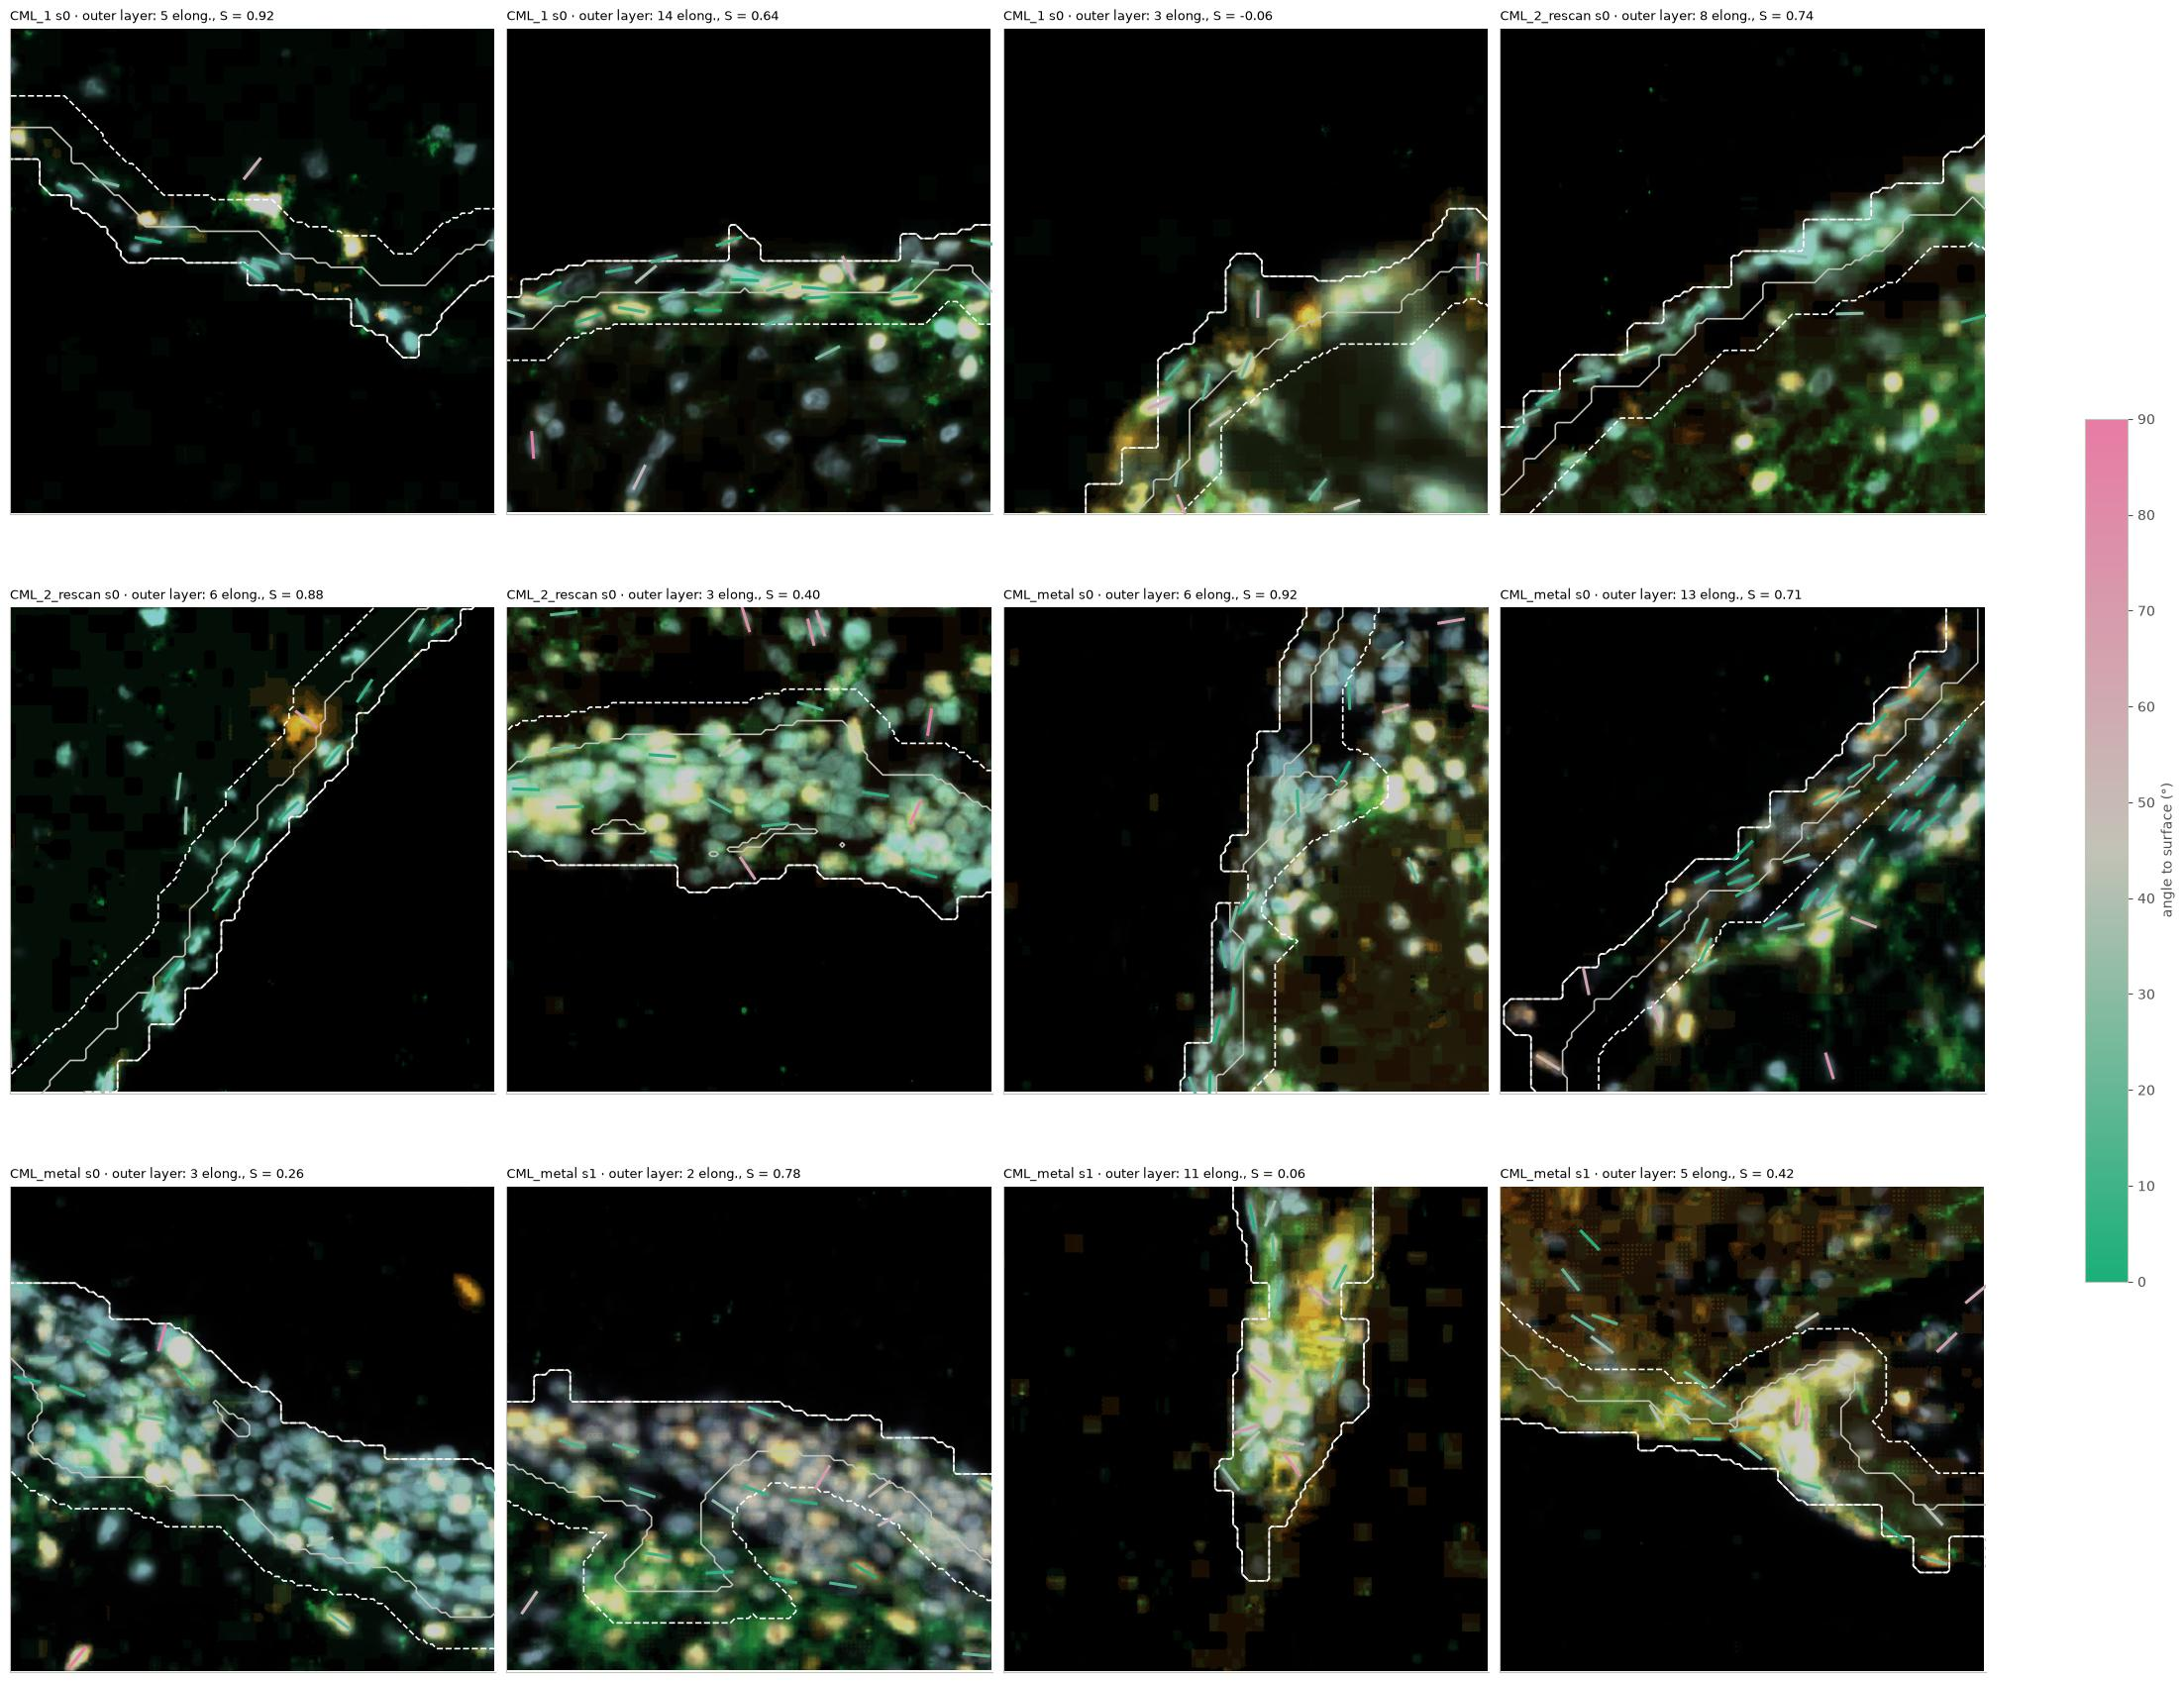

In [6]:
cmap = LinearSegmentedColormap.from_list("angle", ["#1baf7a", "#c3c2b7", "#e87ba4"])
angs = {r.name: O.cell_surface_angles(r) for r in runs}
SIZE = 140
picks = []
for r in runs:
    outer = (r.cells.surface_tier.astype(str) == "meninges") & (r.cells.depth_um <= 10)
    comp = pd.Series(np.where(outer, "outer", None), index=r.cells.index)
    picks += [(r, w) for w in M.random_windows(r.cells, comp, "outer", 3, size_um=SIZE, min_target=8, seed=1)]
fig, axes = plt.subplots(3, 4, figsize=(22, 17.5), layout="constrained")
for ax, (r, (x, y)) in zip(axes.ravel(), picks):
    rgb, ext = R.read_crop_um(r, x, y, SIZE, scale=1.0)
    if rgb is not None:
        ax.imshow(np.clip(rgb * 0.8, 0, 1), extent=ext)
    view = (x - SIZE / 2, x + SIZE / 2, y - SIZE / 2, y + SIZE / 2)
    R.draw_surface(ax, r, view, lw=1.2)
    lc = O.draw_axes(ax, r.cells, angs[r.name], view, cmap=cmap)
    a = angs[r.name].merge(r.cells[["label", "x_um", "y_um", "surface_tier", "depth_um"]], on="label")
    a = a[a.x_um.between(*view[:2]) & a.y_um.between(*view[2:]) & (a.ecc_mom >= M.ELONG_MIN)
          & (a.surface_tier == "meninges") & (a.depth_um <= 10)]
    ax.set_xlim(view[0], view[1]); ax.set_ylim(view[3], view[2]); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{r.name.replace(' scene ', ' s')} · outer layer: {len(a)} elong., S = {O.order_parameter(a.surface_angle):.2f}",
                 loc="left", fontsize=9)
for ax in axes.ravel()[len(picks):]:
    ax.axis("off")
fig.colorbar(lc, ax=axes.ravel().tolist(), shrink=0.5, label="angle to surface (°)")
plt.show()

## Reading

* **Yes – the elongated nuclei of the outer meninges lie along the surface.** In the outer 10 µm,
  S = 0.61 and ~74 % of elongated nuclei are within 30° of the surface (random: 33 %); the shuffle null
  is ≈ 0, so this is the *local* surface, not a slide-wide cutting or scan direction. Higher than the
  section's own parenchyma 20–80 µm under the surface in **17 of 17 sections** (6 animals; median ΔS
  +0.39, 95 % hierarchical-bootstrap CI ~0.37–0.57), and under every check: eccentricity cut-off, surface
  smoothing, well-segmented nuclei, Pu.1⁻ and Pu.1⁺ separately, lesion and control sections.
* **It is a surface property that fades with depth.** Deeper meninges (10–80 µm) are less aligned
  (S ≈ 0.4, lower than the outer layer in 10/12 sections), parenchyma right under the surface only weakly
  (S ≈ 0.2), and from ~100 µm on the alignment is gone or slightly *radial* (S ≈ −0.13 at 150–300 µm,
  beyond its shuffle null) – plausibly radial glial / astrocytic septa of the white matter; not followed up here.
* **Fits flattened pial / arachnoid cells.** Together with notebooks 09–10 (thin, Pu.1⁻-rich, elongated
  outer layer), the orientation is what lining cells stretched along the pia would look like. The
  Pu.1⁺ elongated nuclei of the outer layer are aligned just as strongly – flattened macrophages along the
  surface (meningeal / perivascular macrophages are a candidate) rather than cells migrating inward.
* **Where it fails in the examples:** narrow strands and flaps, where "the surface" lies on both sides and
  its direction is ill-defined, and swollen infiltrate, whose nuclei are round anyway.
* Still no identity marker; orientation is evidence on shape and position only.